# Pelatihan Sistem Deteksi Anemia di Google Colab

Perbandingan **Pipeline 1 (YOLOv8n + U-Net)**, **Pipeline 2 (MediaPipe Face Mesh)**, dan
**Pipeline 2b (MediaPipe MagicTouch)** dengan classifier MobileNetV3-Small, memakai dataset Eyes-defy-anemia.

**Langkah:**
1. Unggah `archive.zip` (dataset Eyes-defy-anemia) ke Google Drive: `MyDrive/anemia-detection-colab/archive.zip`.
2. Menu **Runtime → Change runtime type → T4 GPU → Save**.
3. Menu **Runtime → Run all**, lalu izinkan akses Google Drive saat diminta.
4. Semua hasil (model, laporan, grafik, log) tersimpan otomatis di
   `MyDrive/anemia-detection-colab/hasil/<RUN_NAME>/` setiap kali satu tahap selesai.

**Bila sesi terputus:** buka lagi notebook ini, ubah `START_STEP` ke tahap yang belum selesai
(lihat baris terakhir di `log_pipeline.txt`), biarkan `RUN_NAME` sama, lalu **Run all** lagi.
Hasil tahap yang sudah selesai diambil kembali dari Drive.

**Bila Colab meminta "Restart session" setelah instalasi paket:** klik restart, lalu **Run all** sekali lagi.

**Catatan tampilan:** jangan menambahkan form (`# @title`) ke sel kode, karena sel akan terbelah dan tidak rata. Bila tampilan berantakan, buka ulang notebook ini dari link GitHub.

## Langkah 0. Pengaturan
Ubah `START_STEP` hanya bila melanjutkan run yang terputus. Biarkan `RUN_NAME` sama agar hasil lama terpakai.

In [1]:
# ===== Pengaturan =====
RUN_NAME   = "run_utama"   # nama folder hasil di Drive; samakan untuk melanjutkan run yang terputus
START_STEP = "1"           # 1, 2, 3a, 3b, 4, 5, 6, 7
BRANCH     = "dev"
DRIVE_DIR  = "/content/drive/MyDrive/anemia-detection-colab"

## Langkah 1. Cek GPU
Harus muncul nama GPU (misalnya Tesla T4). Bila error, pilih **Runtime → Change runtime type → T4 GPU**.

In [2]:
# ===== Cek GPU =====
import torch
assert torch.cuda.is_available(), "GPU belum aktif. Pilih Runtime > Change runtime type > T4 GPU, lalu Run all lagi."
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## Langkah 2. Hubungkan Google Drive
Izinkan akses Drive saat diminta. Dataset `archive.zip` dibaca dari Drive dan semua hasil disimpan ke sana.

In [3]:
# ===== Hubungkan Google Drive =====
import os
from google.colab import drive
drive.mount("/content/drive")
ZIP = f"{DRIVE_DIR}/archive.zip"
OUT = f"{DRIVE_DIR}/hasil/{RUN_NAME}"
assert os.path.exists(ZIP), f"archive.zip belum ada. Unggah dataset Eyes-defy-anemia ke {DRIVE_DIR}/ terlebih dahulu."
os.makedirs(OUT, exist_ok=True)
print("Hasil akan disimpan di:", OUT)

Mounted at /content/drive
Hasil akan disimpan di: /content/drive/MyDrive/anemia-detection-colab/hasil/run_utama


## Langkah 3. Ambil kode dari GitHub
Mengunduh kode terbaru branch `dev`.

In [4]:
# ===== Ambil kode dari GitHub =====
REPO = "/content/anemia-detection"
if not os.path.exists(REPO):
    !git clone -q -b {BRANCH} https://github.com/Hatif4706/anemia-detection.git {REPO}
else:
    !git -C {REPO} pull -q origin {BRANCH}
%cd {REPO}
!git log --oneline -1

/content/anemia-detection
77d6090 (HEAD -> dev, origin/dev) chore: lepaskan .venv dari pelacakan git


## Langkah 4. Instal library
Sekitar 1–2 menit. Bila Colab meminta *Restart session*, klik restart lalu **Run all** lagi.

In [5]:
# ===== Instal library (PyTorch + CUDA sudah tersedia di Colab) =====
!pip install -q ultralytics==8.4.174 segmentation-models-pytorch==0.5.0 mediapipe==1.1.0 openpyxl xlrd timm

## Langkah 5. Siapkan dataset dan model MediaPipe
Mengekstrak `archive.zip` dan mengunduh model Face Landmarker serta MagicTouch.

In [6]:
# ===== Siapkan dataset dan model MediaPipe =====
import pathlib, shutil, zipfile, urllib.request
dst = pathlib.Path("data/raw/eyes_defy_anemia")
if not dst.exists():
    tmp = pathlib.Path("/content/tmp_eda")
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(tmp)
    src = next(p for p in tmp.rglob("Italy") if p.is_dir()).parent  # folder yang berisi Italy/ dan India/
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.move(str(src), str(dst))
    shutil.rmtree(tmp, ignore_errors=True)
print("Dataset:", sorted(p.name for p in dst.iterdir()))

pathlib.Path("models").mkdir(exist_ok=True)
MP_MODELS = {
    "face_landmarker.task": "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task",
    "magic_touch.tflite": "https://storage.googleapis.com/mediapipe-models/interactive_segmenter/magic_touch/float32/1/magic_touch.tflite",
}
for name, url in MP_MODELS.items():
    f = pathlib.Path("models") / name
    if not f.exists():
        urllib.request.urlretrieve(url, f)
    print(name, f.stat().st_size // 1024, "KB")

Dataset: ['Dataset anemia.docx', 'India', 'Italy']
face_landmarker.task 3670 KB
magic_touch.tflite 6081 KB


## Langkah 6. Jalankan pipeline (tahap 1–7)
Bagian terlama (sekitar 40 menit di T4). Setiap tahap yang selesai langsung disalin ke Drive.

In [7]:
# ===== Jalankan pipeline per tahap; hasil disalin ke Drive setelah setiap tahap =====
import subprocess, sys

STEPS = ["1", "2", "3a", "3b", "4", "5", "6", "7"]
LOG = f"{OUT}/log_pipeline.txt"

def sync_to_drive():
    for d in ["models", "reports", "runs"]:
        if os.path.exists(d):
            subprocess.run(["rsync", "-a", d, OUT + "/"], check=False)

def run_step(s):
    with open(LOG, "a", encoding="utf-8") as log:
        log.write(f"\n##### TAHAP {s} #####\n")
        p = subprocess.Popen([sys.executable, "-u", "scripts/run_pipeline.py", "--start", s, "--stop", s],
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            if "iCCP" in line:   # peringatan profil warna PNG dari dataset, aman diabaikan
                continue
            print(line, end="")
            log.write(line)
        p.wait()
    sync_to_drive()
    if p.returncode != 0:
        raise RuntimeError(f"Tahap {s} gagal. Lihat log di atas, lalu set START_STEP = '{s}' dan Run all lagi.")
    print(f"--> Tahap {s} selesai dan tersimpan di Drive")

# Ambil kembali hasil tahap sebelumnya dari Drive (untuk melanjutkan run yang terputus)
for d in ["models", "reports", "runs"]:
    if os.path.exists(f"{OUT}/{d}"):
        subprocess.run(["rsync", "-a", f"{OUT}/{d}", "./"], check=False)

start = STEPS.index(START_STEP)
# Data olahan tidak disimpan di Drive (cepat dibuat ulang), jadi siapkan lagi bila sesi baru
if start > 0 and not os.path.exists("data/splits/test.csv"):
    run_step("1")
if START_STEP == "3a" and not os.path.exists("data/processed/yolo/data.yaml"):
    run_step("2")
if START_STEP == "5" and not os.path.exists("data/processed/rois"):
    start = STEPS.index("4")

for s in STEPS[start:]:
    run_step(s)
print("\nSELESAI. Semua hasil ada di Google Drive:", OUT)


1. Metadata dan pembagian data per subjek
{
  "source": "eyes_defy_anemia",
  "n_images": 217,
  "n_anemia": 91,
  "n_non_anemia": 126,
  "split": {
    "train": 151,
    "val": 33,
    "test": 33
  },
  "skipped": [
    "Italy/93: nilai Hb tidak ada"
  ]
}
--> Tahap 1 selesai dan tersimpan di Drive

2. Anotasi bounding box otomatis dari mask
{
  "train": {
    "images": 151,
    "labeled": 151
  },
  "val": {
    "images": 33,
    "labeled": 33
  },
  "test": {
    "images": 33,
    "labeled": 33
  }
}
--> Tahap 2 selesai dan tersimpan di Drive

3a. Pelatihan YOLOv8n
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.174 🚀 Python

## Langkah 7. Ringkasan hasil
Tabel metrik dan gambar utama. Laporan lengkap ada di Drive: `reports/progress/laporan_progres.html`.

Sumber data: **eyes_defy_anemia**  |  commit `77d6090`

| Pipeline | Deteksi ROI (uji) | Dice (uji) | Latensi ROI (ms) | Cakupan klasifikasi | Akurasi | Sensitivity | Specificity | F1 | ROC-AUC |
|---|---|---|---|---|---|---|---|---|---|
| Mask ahli (batas atas) | - | - | - | 100% | 0.849 | 0.786 | 0.895 | 0.815 | 0.944 |
| Pipeline 1: YOLOv8n + U-Net | 97% | 0.833 | 416.11 | 97% | 0.812 | 0.615 | 0.947 | 0.727 | 0.931 |
| Pipeline 2: MediaPipe Face Mesh | 0% | 0.000 | 36.8 | 0% | - | - | - | - | - |
| Pipeline 2b: MediaPipe MagicTouch | 100% | 0.461 | 1880.59 | 100% | 0.849 | 0.929 | 0.789 | 0.839 | 0.865 |

Uji McNemar P1 vs P2: n berpasangan = 0 (tidak ada citra uji yang diproses kedua pipeline)

Uji McNemar P1 vs P2b: n berpasangan = 32, p = 1.0000


anotasi_bbox_dari_mask.png


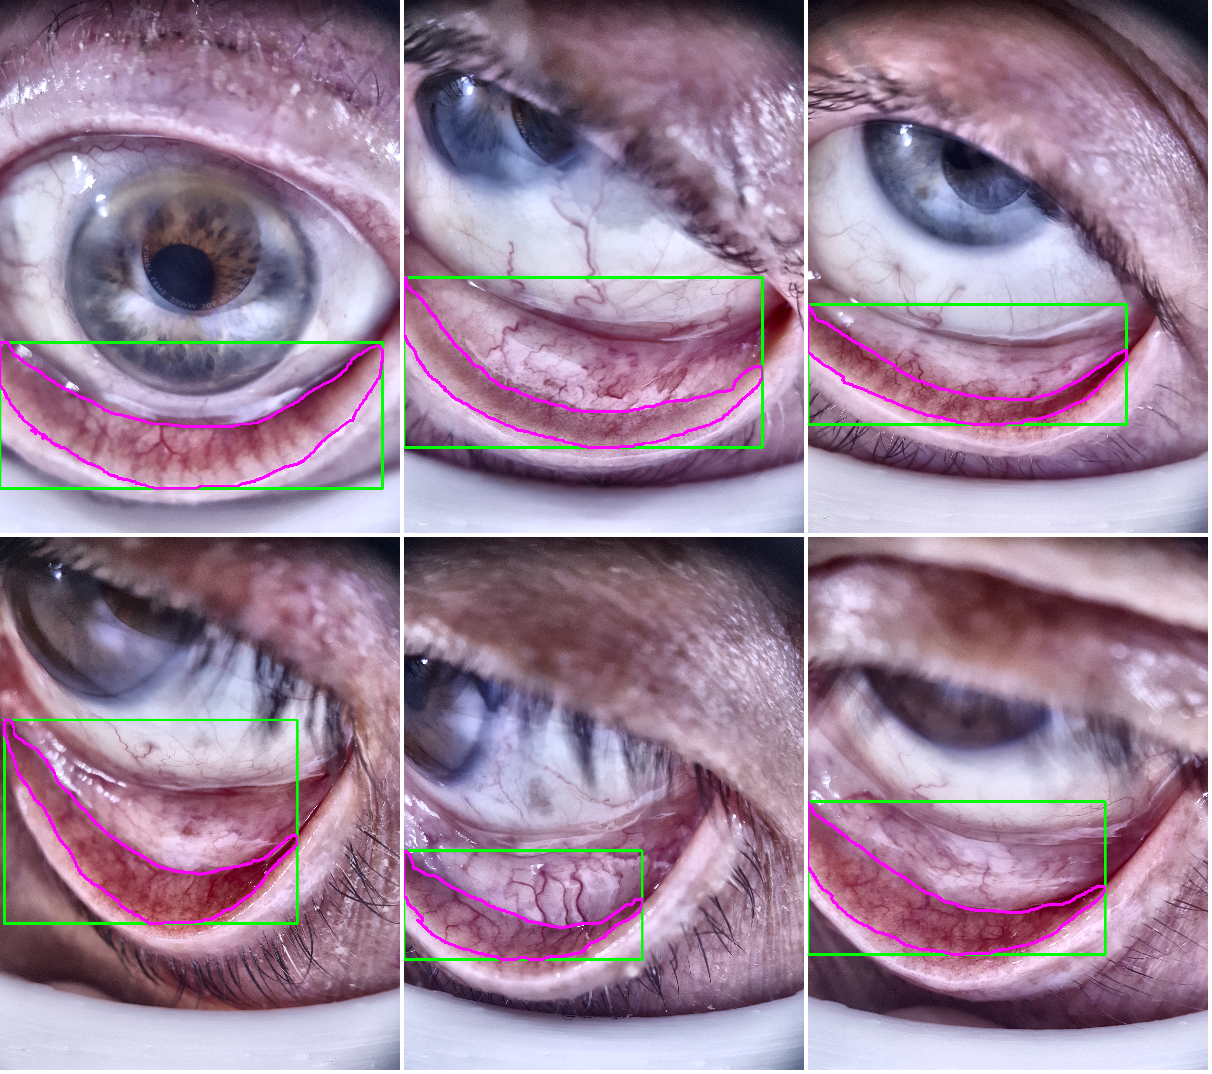

kurva_pelatihan_unet.png


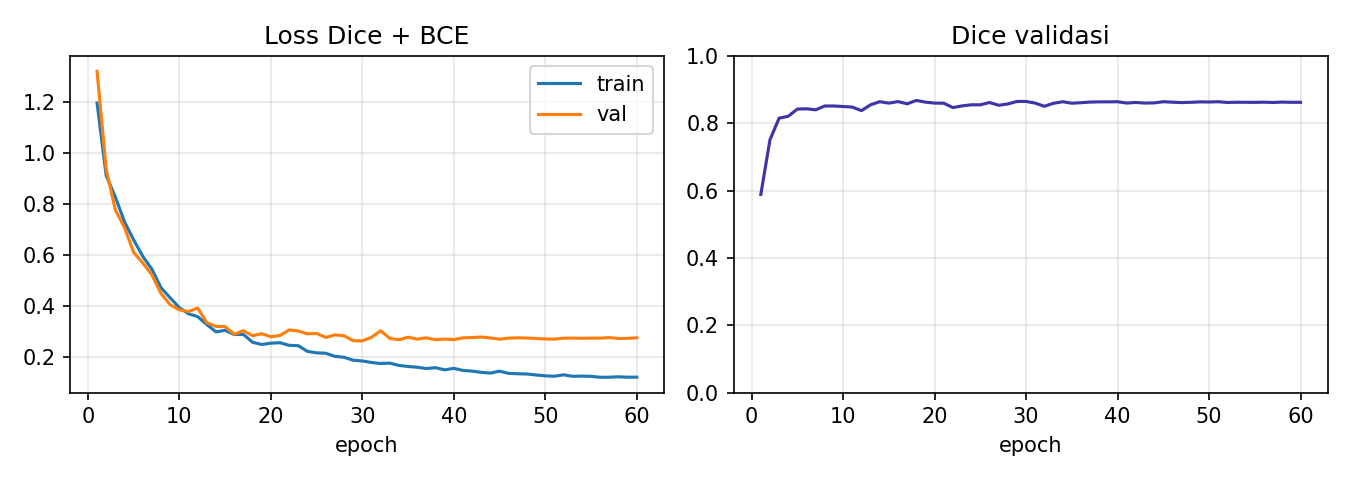

contoh_roi_kedua_pipeline.png


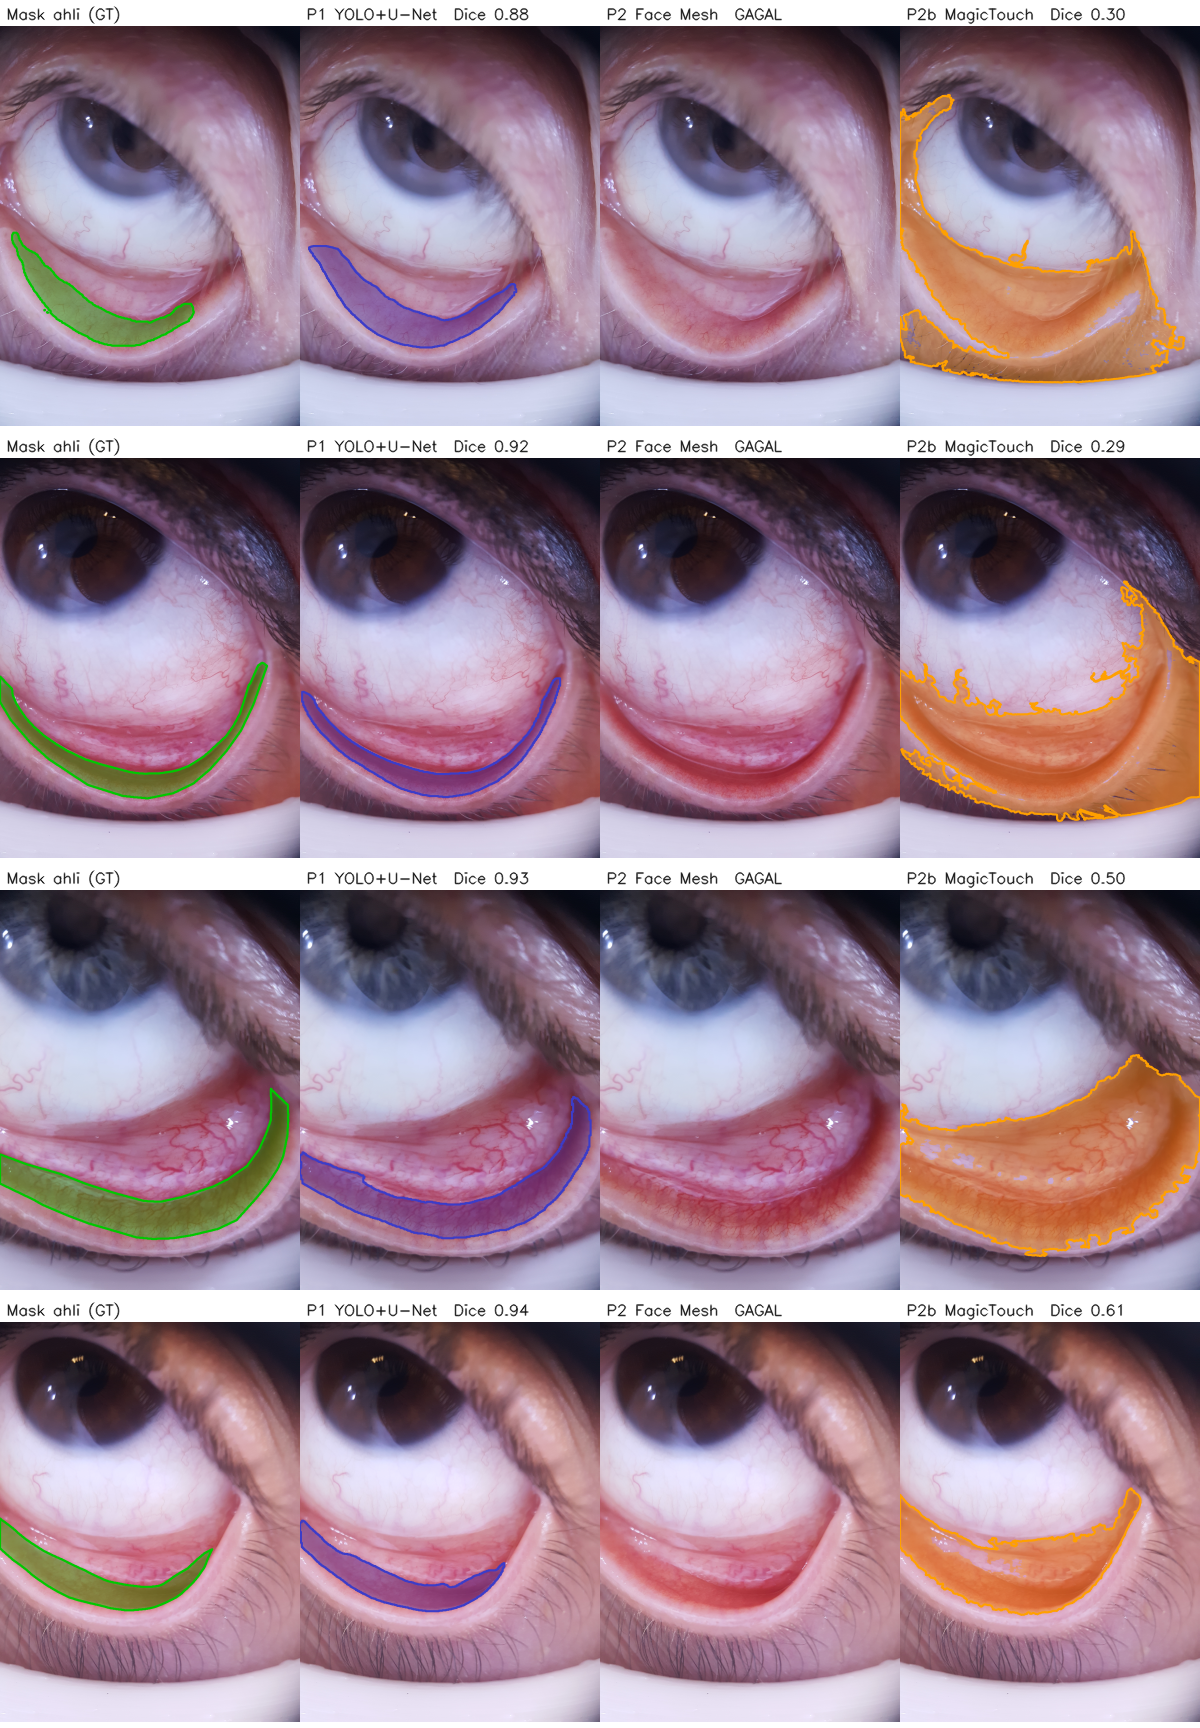

Laporan progres (buka dari Drive): /content/drive/MyDrive/anemia-detection-colab/hasil/run_utama/reports/progress/laporan_progres.html


In [8]:
# ===== Ringkasan hasil =====
from IPython.display import Image, Markdown, display
display(Markdown(open("reports/results_table.md", encoding="utf-8").read()))
for f in ["anotasi_bbox_dari_mask.png", "kurva_pelatihan_unet.png", "contoh_roi_kedua_pipeline.png"]:
    p = f"reports/figures/{f}"
    if os.path.exists(p):
        print(f)
        display(Image(p, width=900))
print("Laporan progres (buka dari Drive):", f"{OUT}/reports/progress/laporan_progres.html")